# 06 · MLP: architecture, tuning and validation results (Phase 2)

**Goal:** show how the MLP was built and tuned, how it trained, and how it compares with our Phase 1 models on the **validation** set.

All numbers here are validation only. The test set is not used in this notebook; it is evaluated once at the end (notebook 08).

The training code is in `src/train_dl.py` and the data pipeline is in `src/dl_data.py`. This notebook only loads the saved outputs in `results/dl/` and plots them.

## 1. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..")
DL = ROOT / "results" / "dl"
FIG = DL / "figures"
FIG.mkdir(parents=True, exist_ok=True)

cfg = json.load(open(DL / "mlp_config.json"))
trials = pd.read_csv(DL / "experiments_dl.csv")
hist = pd.read_csv(DL / "mlp_history.csv")
pred = pd.read_csv(DL / "predictions_mlp_val.csv")
p1 = pd.read_csv(ROOT / "results" / "validation_metrics.csv")
print("trials:", len(trials), "| epochs logged:", len(hist), "| validation rows:", len(pred))

trials: 13 | epochs logged: 29 | validation rows: 26054


## 2. Architecture

A small fully connected network for tabular data: **30 inputs → 128 → 64 → 1**, ReLU activations, dropout after each hidden layer, and a single linear output (the CCME score). The 30 inputs are the same 14 sensor inputs as Phase 1 after preprocessing (median imputation with missing-value flags, scaling, and one-hot encoding of waterbody type and country). The five chemicals behind the CCME formula stay hidden.

In [2]:
widths = cfg["mlp"]["widths"]
sizes = [cfg["n_features"]] + widths + [1]
n_params = sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:]))
print("layers:", " -> ".join(map(str, sizes)))
print("trainable parameters:", f"{n_params:,}")
print({k: v for k, v in cfg["mlp"].items()})
print("early stopping patience:", cfg["early_stopping_patience"], "| max epochs:", cfg["max_epochs"], "| seed:", cfg["seed"])

layers: 30 -> 128 -> 64 -> 1
trainable parameters: 12,289
{'widths': [128, 64], 'dropout': 0.2, 'weight_decay': 0.0001, 'batch_norm': False, 'lr': 0.001, 'loss': 'mse', 'batch_size': 512}
early stopping patience: 10 | max epochs: 60 | seed: 42


## 3. Tuning

13 configurations were tried (the default and 12 random ones: width, dropout, weight decay, learning rate, batch size, loss). Each was trained with early stopping and compared on **validation RMSE** only. The default setting came out on top, and nearly every other trial landed within a narrow band, which says the result is not sensitive to these choices.

In [3]:
show = trials.sort_values("val_rmse")[["trial", "widths", "dropout", "weight_decay", "lr", "loss", "batch_size",
                                         "best_epoch", "val_mae", "val_rmse", "val_r2", "selected"]]
show.round({"val_mae": 3, "val_rmse": 3, "val_r2": 3})

,trial,widths,dropout,weight_decay,lr,loss,batch_size,best_epoch,val_mae,val_rmse,val_r2,selected
0,0,"(128, 64)",0.2,0.00010,0.0010,mse,512,19,7.767,11.231,0.345,True
2,2,"(64, 32)",0.0,0.00100,0.0003,mse,256,35,7.935,11.241,0.344,False
6,6,"(256, 128)",0.0,0.00000,0.0010,mse,512,7,7.687,11.242,0.343,False
10,10,"(128, 64)",0.2,0.00000,0.0003,mse,512,35,7.860,11.245,0.343,False
3,3,"(128, 64)",0.1,0.00000,0.0030,mse,1024,19,7.844,11.263,0.341,False
1,1,"(64, 32)",0.0,0.00010,0.0003,mse,256,19,7.844,11.289,0.338,False
12,12,"(128, 64)",0.2,0.00000,0.0030,mse,1024,19,7.848,11.293,0.337,False
9,9,"(256, 128, 64)",0.2,0.00001,0.0030,mse,256,7,7.999,11.326,0.334,False
5,5,"(128, 64)",0.3,0.00010,0.0010,mse,256,15,7.843,11.329,0.333,False
7,7,"(256, 128)",0.2,0.00000,0.0030,huber,1024,9,7.498,11.387,0.326,False


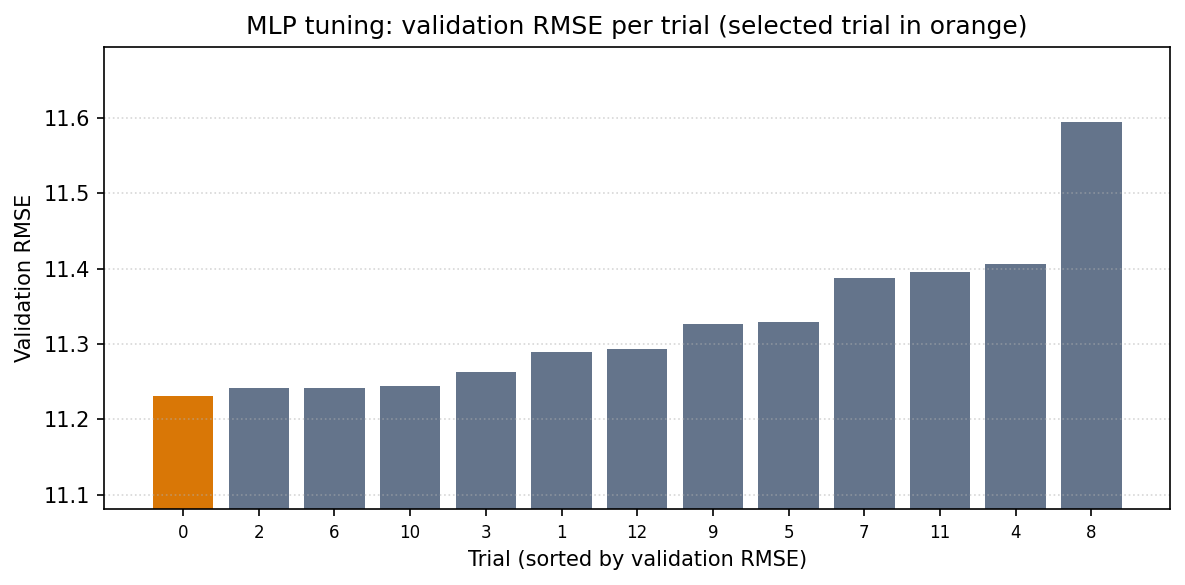

spread of RMSE across trials: 0.363


In [4]:
t = trials.sort_values("val_rmse").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 4), dpi=150)
colors = ["#d97706" if s else "#64748b" for s in t["selected"]]
ax.bar(range(len(t)), t["val_rmse"], color=colors)
ax.set_xticks(range(len(t)))
ax.set_xticklabels(t["trial"], fontsize=8)
ax.set_xlabel("Trial (sorted by validation RMSE)")
ax.set_ylabel("Validation RMSE")
ax.set_ylim(t["val_rmse"].min() - 0.15, t["val_rmse"].max() + 0.1)
ax.set_title("MLP tuning: validation RMSE per trial (selected trial in orange)")
ax.grid(axis="y", ls=":", alpha=0.5)
plt.tight_layout()
plt.savefig(FIG / "mlp_tuning_trials.png")
plt.show()
print("spread of RMSE across trials:", round(t["val_rmse"].max() - t["val_rmse"].min(), 3))

**Reading:** the selected configuration (lowest RMSE) is the default one. Huber loss lowered MAE a little but raised RMSE, so it was not chosen because we select on RMSE.

## 4. Training behaviour

Loss is on the standardised target. Training stops when validation loss has not improved for 10 epochs, and the weights from the best epoch are kept.

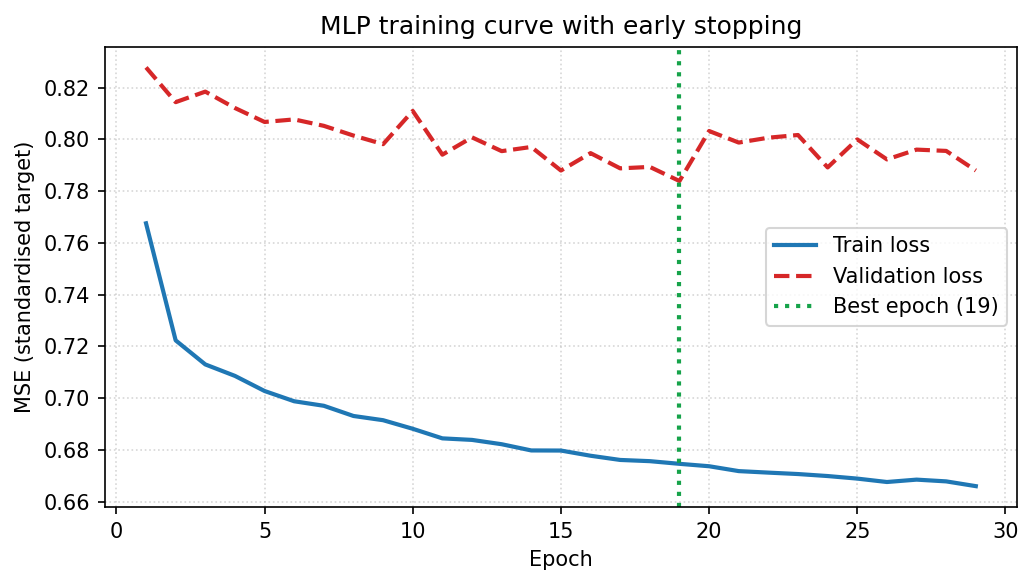

epochs run: 29 | best epoch: 19 | validation loss at best: 0.7839


In [5]:
best = int(hist["val_mse_std"].idxmin())
best_epoch = int(hist.loc[best, "epoch"])
fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
ax.plot(hist["epoch"], hist["train_loss"], label="Train loss", color="#1f77b4", lw=2)
ax.plot(hist["epoch"], hist["val_mse_std"], label="Validation loss", color="#d62728", lw=2, ls="--")
ax.axvline(best_epoch, color="#16a34a", ls=":", lw=2, label=f"Best epoch ({best_epoch})")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE (standardised target)")
ax.set_title("MLP training curve with early stopping")
ax.grid(ls=":", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "mlp_training_curve.png")
plt.show()
print("epochs run:", int(hist["epoch"].max()), "| best epoch:", best_epoch,
      "| validation loss at best:", round(hist.loc[best, "val_mse_std"], 4))

**Reading:** validation loss reaches its lowest value at epoch 19 and never improves on it afterwards; it hovers around 0.79 to 0.80 while training loss keeps falling slowly. After 10 epochs without improvement training stops (epoch 29) and the epoch-19 weights are restored. This is the evidence for the early-stopping row in the regularisation table.

## 5. Validation results against Phase 1

Same validation stations, same inputs. Lower is better for MAE and RMSE; higher is better for R².

In [6]:
names = {"XGBRegressor": "XGBoost", "RandomForestRegressor": "Random Forest", "Ridge": "Ridge", "DummyRegressor": "Mean baseline"}
cmp = p1[["model", "mae", "rmse", "r2"]].copy()
cmp["model"] = cmp["model"].map(names)
m = cfg["validation_metrics"]
cmp.loc[len(cmp)] = ["MLP (Phase 2)", m["mae"], m["rmse"], m["r2"]]
cmp = cmp.sort_values("rmse").reset_index(drop=True)
cmp.round(3)

,model,mae,rmse,r2
0,XGBoost,7.729,11.205,0.348
1,MLP (Phase 2),7.767,11.231,0.345
2,Random Forest,7.773,11.247,0.343
3,Ridge,8.688,12.263,0.219
4,Mean baseline,9.762,13.912,-0.005


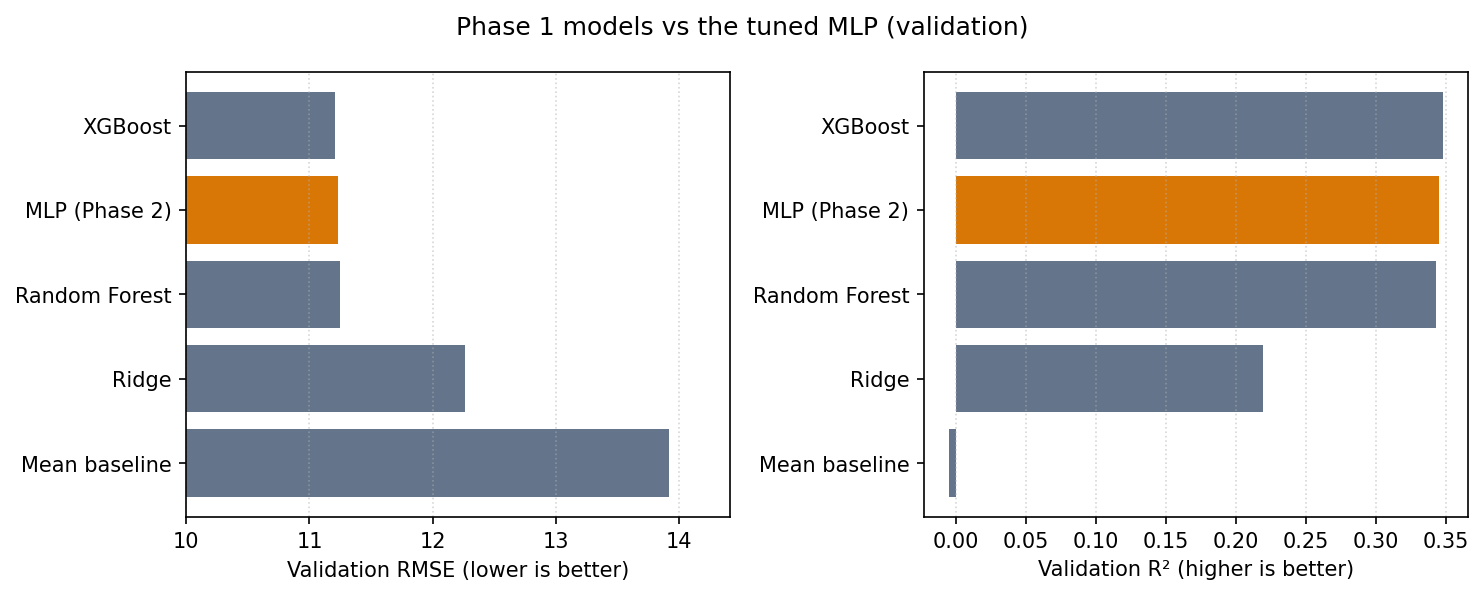

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=150)
col = ["#d97706" if "MLP" in n else "#64748b" for n in cmp["model"]]
axes[0].barh(cmp["model"], cmp["rmse"], color=col); axes[0].invert_yaxis()
axes[0].set_xlabel("Validation RMSE (lower is better)"); axes[0].set_xlim(10, cmp["rmse"].max() + 0.5)
axes[1].barh(cmp["model"], cmp["r2"], color=col); axes[1].invert_yaxis()
axes[1].set_xlabel("Validation R² (higher is better)")
for a in axes: a.grid(axis="x", ls=":", alpha=0.5)
plt.suptitle("Phase 1 models vs the tuned MLP (validation)")
plt.tight_layout()
plt.savefig(FIG / "mlp_vs_phase1_validation.png")
plt.show()

**Reading:** the MLP (R² about 0.345) sits right next to XGBoost (0.348) and Random Forest (0.343), and well above Ridge (0.219). So on this table of 14 inputs a small network matches the tree models but does not beat them. Whether the small gaps are real is tested with station-bootstrap intervals in notebook 08, not here.

## 6. Where the MLP is wrong

Predicted against actual CCME score, and the average bias by true score band. The Phase 1 finding that polluted water is predicted too high is worth checking for the MLP too.

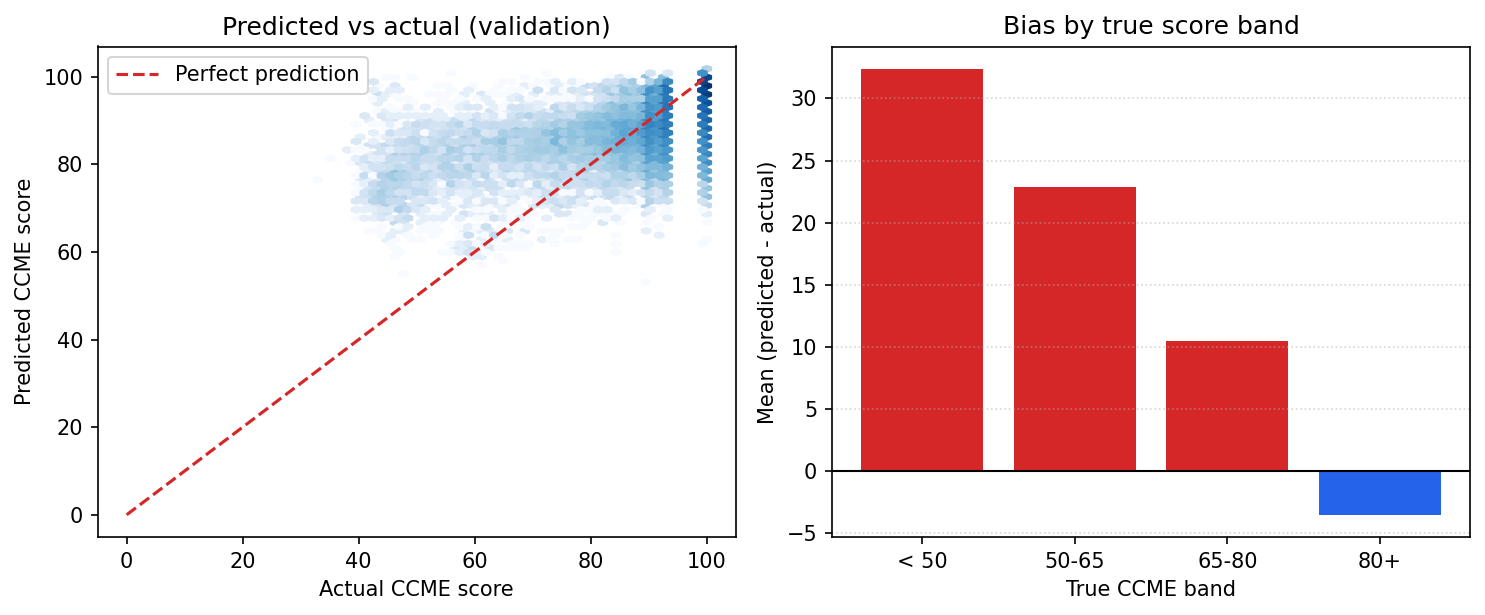

,true score band,rows,mean bias (pred - true),MAE
0,< 50,872,32.39,32.39
1,50-65,1376,22.90,22.95
2,65-80,2272,10.46,11.09
3,80+,21534,-3.50,5.45


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), dpi=150)
ax = axes[0]
ax.hexbin(pred["y_true"], pred["y_pred"], gridsize=45, cmap="Blues", mincnt=1, bins="log")
ax.plot([0, 100], [0, 100], color="#d62728", ls="--", lw=1.5, label="Perfect prediction")
ax.set_xlabel("Actual CCME score"); ax.set_ylabel("Predicted CCME score")
ax.set_title("Predicted vs actual (validation)"); ax.legend(loc="upper left")

bands = [(0, 50, "< 50"), (50, 65, "50-65"), (65, 80, "65-80"), (80, 101, "80+")]
rows = []
for lo, hi, lab in bands:
    mask = (pred["y_true"] >= lo) & (pred["y_true"] < hi)
    err = pred.loc[mask, "y_pred"] - pred.loc[mask, "y_true"]
    rows.append((lab, int(mask.sum()), err.mean(), err.abs().mean()))
bias = pd.DataFrame(rows, columns=["true score band", "rows", "mean bias (pred - true)", "MAE"])
axes[1].bar(bias["true score band"], bias["mean bias (pred - true)"],
            color=["#d62728" if b > 0 else "#2563eb" for b in bias["mean bias (pred - true)"]])
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("True CCME band"); axes[1].set_ylabel("Mean (predicted - actual)")
axes[1].set_title("Bias by true score band"); axes[1].grid(axis="y", ls=":", alpha=0.5)
plt.tight_layout()
plt.savefig(FIG / "mlp_pred_vs_actual_bias.png")
plt.show()
bias.round(2)

**Reading:** the MLP predicts polluted water (true score under 50) about 32 points too high, and the bias shrinks steadily as the true score rises (it slightly underpredicts the cleanest water). The model is pulled toward the middle of the score range, which matches what XGBoost does. This weakness is shared by both model families, so it is a limit of the inputs rather than of the network, and it is the main thing the hybrid and the error analysis should look at.

## 7. Takeaways

- The tuned MLP is **30 → 128 → 64 → 1** (about 12,000 parameters) with dropout 0.2, weight decay 1e-4, Adam (lr 1e-3), batch size 512, MSE loss and early stopping.
- Tuning barely mattered: almost every configuration landed in the same narrow RMSE band, and the default won.
- Validation RMSE 11.231, MAE 7.767, R² 0.345: comparable to XGBoost, clearly better than Ridge.
- Early stopping is what keeps it from overfitting (best epoch 19 of 29 run).
- Like XGBoost it overpredicts polluted water by about 32 points.
- Next: ablations (`src/ablations.py`), the hybrid (notebook 07) and the one-time test evaluation (notebook 08).